# 1. Import and Hardware Setup

In [58]:
import torch
import torch.nn as nn
import torch.optim as optim
import torch.functional as F
from torch.utils.data import Dataset, DataLoader
import torch.nn.functional as F
from torchvision import transforms, models
from PIL import Image, ImageDraw, ImageFont
import os
import random
import math
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import numpy as np
import glob
import json
import gc

!pip install tqdm kagglehub albumentations timm -q
import timm
import kagglehub
from tqdm.auto import tqdm

import albumentations as A
from albumentations.pytorch import ToTensorV2


# Set device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using: {device}")

Using: cuda


# 2. Hyperparameters

In [59]:
# Image settings
IMG_SIZE = 416  # Starting size
MULTI_SCALES = [320, 352, 384, 416, 448, 480, 512, 544, 576, 608]
SCALE_INTERVAL = 10
IN_CHANNELS = 3
NUM_CLASSES = 20

# Class names
CLASS_NAMES = [
    "aeroplane",  # 0
    "bicycle",  # 1
    "bird",  # 2
    "boat",  # 3
    "bottle",  # 4
    "bus",  # 5
    "car",  # 6
    "cat",  # 7
    "chair",  # 8
    "cow",  # 9
    "diningtable",  # 10
    "dog",  # 11
    "horse",  # 12
    "motorbike",  # 13
    "person",  # 14
    "pottedplant",  # 15
    "sheep",  # 16
    "sofa",  # 17
    "train",  # 18
    "tvmonitor",  # 19
]

# Training settings
BATCH_SIZE = 16
LR = 1e-4
EPOCHS = 100
SEED = 42
WEIGHT_DECAY = 5e-4

# Backbone freeze and warmup settings
WARMUP_EPOCHS = 5
FREEZE_BACKBONE_EPOCHS = 5

# YOLOv3 settings
STRIDES = [
    32,
    16,
    8,
]  # 3 detection scales: the feature maps are 13x13, 26x26, 52x52 for 416x416
NUM_ANCHORS_PER_SCALE = 3  # 3 anchor priors per scale (9 total)

# Loss weighting
LAMBDA_COORD = 1.0  # Weight for coordinate loss
LAMBDA_NOOBJ = 1.0  # Weight for no-object confidence loss
LAMBDA_OBJ = 1.0  # Weight for object confidence loss
LAMBDA_CLASS = 1.0  # Weight for class loss

# Detection thresholds
CONF_THRESHOLD = 0.5
NMS_THRESHOLD = 0.45
IGNORE_IOU_THRESHOLD = 0.5  # IoU threshold to ignore negative anchors during training

PATIENCE = 10

# 3. Dataset Download

In [60]:
# Download Pascal VOC 2012 object detection dataset via kagglehub
DATASET_PATH = kagglehub.dataset_download("banuprasadb/pascal-voc-2012")
print(f"Dataset downloaded to: {DATASET_PATH}")


# Auto-detect the actual root
def find_split_root(base_path):
    """Find the directory that directly contains train/ and val/ subfolders."""
    # Check if the splits are directly under base_path
    if all(os.path.isdir(os.path.join(base_path, s)) for s in ["train", "val"]):
        return base_path

    # Otherwise search one level deeper
    for entry in os.listdir(base_path):
        candidate = os.path.join(base_path, entry)
        if os.path.isdir(candidate):
            if all(os.path.isdir(os.path.join(candidate, s)) for s in ["train", "val"]):
                return candidate
    raise FileNotFoundError(f"Could not find train/val directories under {base_path}")


DATA_ROOT = find_split_root(DATASET_PATH)
print(f"Data root: {DATA_ROOT}")

# Verify folder structure
for split in ["train", "val"]:
    img_dir = os.path.join(DATA_ROOT, split, "images")
    lbl_dir = os.path.join(DATA_ROOT, split, "labels")
    n_images = len(glob.glob(os.path.join(img_dir, "*")))
    n_labels = len(glob.glob(os.path.join(lbl_dir, "*.txt")))
    print(f"{split}: {n_images} images, {n_labels} label files")

Dataset downloaded to: /kaggle/input/datasets/banuprasadb/pascal-voc-2012
Data root: /kaggle/input/datasets/banuprasadb/pascal-voc-2012
train: 16551 images, 16551 label files
val: 4952 images, 4952 label files


# 4. Data Preparation

**Data Pipeline:**
1. **YOLO Format Parsing:** Each .txt label file has rows of `class_id, x_center, y_center, width height` (normalized 0-1)
2. **Coordinate Conversion**: Convert YOLO format to absolute `[xmin, ymin, xmax, ymax]` cooridnates, then normalize to YOLO1's 448x448 input.
3. **Augmentation** (training only)
4. **Custom collate**: Since each image has a different number of objects, use a custom `collate_fn`

In [61]:
def set_seed(seed: int = 42):
    """Set all random seeds for reproducibility."""
    os.environ["PYTHONHASHSEED"] = str(seed)
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


def seed_worker(worker_id):
    """Seed function for DataLoader workers to ensure reproducibility."""
    worker_seed = SEED + worker_id
    np.random.seed(worker_seed)
    random.seed(worker_seed)


set_seed(SEED)

In [62]:
class VOCDataset(Dataset):
    """YOLO format labels

    Each sample returns:
        image: (3, 448, 448) normalized tensor
        boxes: (N, 4) in fractional [xmin, ymin, xmax, ymax] format
        labels: (N, ) class indices (0-19), no background offset
    """

    def __init__(self, data_root, split="train", img_size=448):
        self.img_size = img_size
        self.split = split
        self.img_dir = os.path.join(data_root, split, "images")
        self.lbl_dir = os.path.join(data_root, split, "labels")

        # Collect all image paths
        self.image_paths = sorted(
            glob.glob(os.path.join(self.img_dir, "*jpg"))
            + glob.glob(os.path.join(self.img_dir, "*jpeg"))
            + glob.glob(os.path.join(self.img_dir, "*png"))
        )
        assert len(self.image_paths) > 0, f"No images found in {self.img_dir}"

        # Data Augmentation with Albumentations
        if split == "train":
            self.transform = A.Compose(
                [
                    A.ColorJitter(
                        brightness=0.125, contrast=0.5, saturation=0.5, hue=0.05, p=0.5
                    ),
                    A.BBoxSafeRandomCrop(erosion_rate=0.0, p=0.5),
                    A.HorizontalFlip(p=0.5),
                    A.Resize(height=img_size, width=img_size, p=1.0),
                    A.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
                    ToTensorV2(),
                ],
                bbox_params=A.BboxParams(
                    format="albumentations",
                    label_fields=["class_labels"],
                    min_visibility=0.1,
                ),
            )
        else:
            self.transform = A.Compose(
                [
                    A.Resize(height=img_size, width=img_size, p=1.0),
                    A.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
                    ToTensorV2(),
                ],
                bbox_params=A.BboxParams(
                    format="albumentations",
                    label_fields=["class_labels"],
                    min_visibility=0.1,
                ),
            )

    def __len__(self):
        return len(self.image_paths)

    def _parse_yolo_label(self, label_path):
        """Parse a YOLO-format label file and return boxes + labels in albumentations format."""
        boxes = []
        labels = []

        if not os.path.exists(label_path):
            return [], []

        with open(label_path, "r") as f:
            for line in f:
                parts = line.strip().split()
                if len(parts) < 5:
                    continue

                cls_id = int(parts[0])
                x_center = float(parts[1])
                y_center = float(parts[2])
                w = float(parts[3])
                h = float(parts[4])

                xmin = x_center - w / 2.0
                ymin = y_center - h / 2.0
                xmax = x_center + w / 2.0
                ymax = y_center + h / 2.0

                xmin = max(0.0, min(1.0, xmin))
                ymin = max(0.0, min(1.0, ymin))
                xmax = max(0.0, min(1.0, xmax))
                ymax = max(0.0, min(1.0, ymax))

                if xmax <= xmin or ymax <= ymin:
                    continue

                boxes.append([xmin, ymin, xmax, ymax])
                labels.append(cls_id)

        return boxes, labels

    def __getitem__(self, idx):
        # Load images as numpy array (RGB)
        img_path = self.image_paths[idx]
        image = Image.open(img_path).convert("RGB")
        image = np.array(image)

        # Load corresponding label
        img_basename = os.path.splitext(os.path.basename(img_path))[0]
        label_path = os.path.join(self.lbl_dir, f"{img_basename}.txt")
        boxes, labels = self._parse_yolo_label(label_path)

        # Apply Albumentations
        try:
            transformed_img = self.transform(
                image=image, bboxes=boxes, class_labels=labels
            )
            image = transformed_img["image"]
            boxes = transformed_img["bboxes"]
            labels = transformed_img["class_labels"]
        except Exception as e:
            # Fallback for edge cases
            fallback_transform = A.Compose(
                [
                    A.Resize(height=self.img_size, width=self.img_size, p=1.0),
                    A.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
                    ToTensorV2(),
                ],
                bbox_params=A.BboxParams(
                    format="albumentations", label_fields=["class_labels"]
                ),
            )
            transformed_img = fallback_transform(
                image=image, bboxes=boxes, class_labels=labels
            )
            image = transformed_img["image"]
            boxes = transformed_img["bboxes"]
            labels = transformed_img["class_labels"]

        # Convert ouputs to torch tensors
        if len(boxes) == 0:
            boxes = torch.zeros((0, 4), dtype=torch.float32)
            labels = torch.zeros((0,), dtype=torch.long)
        else:
            boxes = torch.tensor(boxes, dtype=torch.float32)
            labels = torch.tensor(labels, dtype=torch.long)

        return image, boxes, labels


def collate_fn(batch):
    """Custom collate function for variable-length bounding box targets.

    Returns:
        images: (B, 3, H, W) tensor
        boxes: list of B tensors, each (N_i, 4)
        labels: list of B tensors, each (N_i)
    """
    images = []
    boxes = []
    labels = []

    for img, bx, lbl in batch:
        images.append(img)
        boxes.append(bx)
        labels.append(lbl)

    images = torch.stack(images, dim=0)
    return images, boxes, labels

In [63]:
# Build datasets and dataloaders
train_dataset = VOCDataset(data_root=DATA_ROOT, split="train", img_size=IMG_SIZE)
val_dataset = VOCDataset(data_root=DATA_ROOT, split="val", img_size=IMG_SIZE)

train_generator = torch.Generator().manual_seed(SEED)
eval_generator = torch.Generator().manual_seed(SEED)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    persistent_workers=True,
    worker_init_fn=seed_worker,
    generator=train_generator,
    pin_memory=True,
    collate_fn=collate_fn,
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    persistent_workers=True,
    worker_init_fn=seed_worker,
    generator=eval_generator,
    pin_memory=True,
    collate_fn=collate_fn,
)

print(f"Train: {len(train_dataset)} images, {len(train_loader)} batches")
print(f"Val:   {len(val_dataset)} images, {len(val_loader)} batches")


Train: 16551 images, 1035 batches
Val:   4952 images, 310 batches


In [64]:
import os
import numpy as np


def iou_wh(boxes, centroids):
    """Compute IoU."""
    boxes = boxes[:, np.newaxis, :]  # (N, 1, 2)
    centroids = centroids[np.newaxis, :, :]  # (1, k, 2)

    inter_w = np.minimum(boxes[..., 0], centroids[..., 0])
    inter_h = np.minimum(boxes[..., 1], centroids[..., 1])
    inter_area = inter_w * inter_h

    box_area = boxes[..., 0] * boxes[..., 1]
    cent_area = centroids[..., 0] * centroids[..., 1]
    union_area = box_area + cent_area - inter_area

    return inter_area / np.clip(union_area, a_min=1e-6, a_max=None)


def kmeans_anchors(boxes_wh, k=9, max_iters=300):
    """K-Means Clustering with distance d = 1 - IoU."""
    # Random initialize the centers
    indices = np.random.choice(len(boxes_wh), size=k, replace=False)
    centroids = boxes_wh[indices].copy()

    for _ in range(max_iters):
        ious = iou_wh(boxes_wh, centroids)  # (N, k)
        cluster_assignments = np.argmax(ious, axis=1)

        new_centroids = np.zeros_like(centroids)
        for cluster_idx in range(k):
            assigned = boxes_wh[cluster_assignments == cluster_idx]
            if len(assigned) > 0:
                new_centroids[cluster_idx] = np.mean(assigned, axis=0)
            else:
                new_centroids[cluster_idx] = boxes_wh[np.random.choice(len(boxes_wh))]

        if np.allclose(centroids, new_centroids, atol=1e-2):
            break
        centroids = new_centroids

    mean_iou = np.mean(np.max(iou_wh(boxes_wh, centroids), axis=1))
    print(f"Mittlerer IoU der gewählten Anchors: {mean_iou * 100:.2f}%")

    return centroids


# 1. Read all (w, h) from YOLO-.txt-files:
all_wh = []
for img_path in train_dataset.image_paths:
    img_basename = os.path.splitext(os.path.basename(img_path))[0]
    label_path = os.path.join(train_dataset.lbl_dir, f"{img_basename}.txt")

    if os.path.exists(label_path):
        with open(label_path, "r") as f:
            for line in f:
                parts = line.strip().split()
                if len(parts) >= 5:
                    # In YOLO: parts[3] = w (normed), parts[4] = h (normed)
                    w = float(parts[3]) * IMG_SIZE
                    h = float(parts[4]) * IMG_SIZE
                    if w > 0 and h > 0:
                        all_wh.append([w, h])

boxes_wh = np.array(all_wh, dtype=np.float32)
print(f"Insgesamt {len(boxes_wh)} Bounding Boxes geladen.")

# 2. 9 Cluster determine:
voc_anchors = kmeans_anchors(boxes_wh, k=9)

# 3. Sort by area:
areas = voc_anchors[:, 0] * voc_anchors[:, 1]
sorted_anchors = voc_anchors[np.argsort(areas)]
sorted_anchors = np.round(sorted_anchors).astype(int).tolist()

# 4. Devide in 3 scales:
ANCHORS = [
    [tuple(a) for a in sorted_anchors[6:9]],  # Scale 0 (13x13): big objects
    [tuple(a) for a in sorted_anchors[3:6]],  # Scale 1 (26x26): mid objects
    [tuple(a) for a in sorted_anchors[0:3]],  # Scale 2 (52x52): small objects
]

print("\nGenerating VOC-Anchors for the Training:")
print(ANCHORS)


Insgesamt 40058 Bounding Boxes geladen.
Mittlerer IoU der gewählten Anchors: 67.96%

Generating VOC-Anchors for the Training:
[[(187, 306), (331, 244), (347, 372)], [(134, 153), (99, 262), (271, 148)], [(30, 53), (88, 77), (53, 149)]]


# 5. YOLOv3 Architecture

- Use `Darknet-53`as backbone (53 conv layers with residual connections)
- Detects objects at **3 different scales** using a Feature Pyramid Network (FPN):
    - Scale 0: 13x13 grid (stride 32) for large objects
    - Scale 1: 26x26 grid (stride 16) for medium objects
    - Scale 2: 52x52 grid (stride 8)  for small objects
- Each grid cell at each scale has **3 anchor priors** (9 total anchors across scales)
- Each anchor predicts: `(tx, ty, tw, th, objectness, c0, c1, ..., c19)` = **25 values** (for 20 classes)
- Box center: `bx = sigmoid(tx) + cx`, `by = sigmoid(ty) + cy`
- Box size: `bw = pw * exp(tw)`, `bh = ph * exp(th)` where `(pw, ph)` are anchor dimensions

- Objectness: logistic (sigmoid) activation - independent per anchor
- Class scores: independent logistic (sigmoid) per class
- Loss: Binaray cross-entropy for objectness and class predictions; MSE for box coordinates

**Pretrained Feature Extractor**:
- ImageNet-pretrained **Darknet-53** backbone from `timm`
- Extract features at 3 stages and build FPN-style detection heads.

## 5.1 Utility Functions for Anchor-Based Target Encoding

In [65]:
def compute_iou(boxes_a, boxes_b):
    """Compute IoU between two sets of boxes.

    Args:
        boxes_a: (A, 4) in [xmin, ymin, xmax, ymax]
        boxes:b: (B, 4) in [xmin, ymin, xmax, ymax]

    Returns:
        (A, B) IoU matrix
    """
    A = boxes_a.size(0)
    B = boxes_b.size(0)

    # Intersection coordinates
    max_xy = torch.min(
        boxes_a[:, 2:].unsqueeze(1).expand(A, B, 2),
        boxes_b[:, 2:].unsqueeze(0).expand(A, B, 2),
    )
    min_xy = torch.max(
        boxes_a[:, :2].unsqueeze(1).expand(A, B, 2),
        boxes_b[:, :2].unsqueeze(0).expand(A, B, 2),
    )

    inter = torch.clamp(max_xy - min_xy, min=0)  # (A, B, 2)
    inter_area = inter[:, :, 0] * inter[:, :, 1]  # (A, B)

    # Areas
    area_a = (
        ((boxes_a[:, 2] - boxes_a[:, 0]) * (boxes_a[:, 3] - boxes_a[:, 1]))
        .unsqueeze(1)
        .expand(A, B)
    )
    area_b = (
        ((boxes_b[:, 2] - boxes_b[:, 0]) * (boxes_b[:, 3] - boxes_b[:, 1]))
        .unsqueeze(0)
        .expand(A, B)
    )

    return inter_area / (area_a + area_b - inter_area + 1e-6)


def compute_iou_wh(wh1, wh2):
    """Compute IoU between anchor dimensions and GT box dimensions (centered at origin)

    Used for assigning GT boxes to anchor priors based on shape similarity.

    Args:
        wh1: (N, 2) widths and heights of set 1
        wh2: (M, 2) widths and heights of set 2

    Returns:
        (N, M) IoU matrix (both boxes centered at origin)
    """
    # Intersection = min(w1, w2) * min(h1*h2)
    inter_w = torch.min(wh1[:, 0].unsqueeze(1), wh2[:, 0].unsqueeze(0))
    inter_h = torch.min(wh1[:, 1].unsqueeze(1), wh2[:, 1].unsqueeze(0))
    inter_area = inter_w * inter_h

    area1 = (wh1[:, 0] * wh1[:, 1]).unsqueeze(1)
    area2 = (wh2[:, 0] * wh2[:, 1]).unsqueeze(0)

    return inter_area / (area1 + area2 - inter_area + 1e-6)


def build_yolov3_targets(
    boxes, labels, anchors, strides, img_size, num_classes, ignore_iou_threshold=0.5
):
    device = boxes.device
    num_scales = len(strides)
    num_anchor_per_scale = len(anchors[0])

    # Build target tensors for each scale on the same device as input boxes
    targets = []
    for s_idx in range(num_scales):
        grid_size = img_size // strides[s_idx]
        target = torch.zeros(
            num_anchor_per_scale,
            grid_size,
            grid_size,
            6 + num_classes,
            device=device,
            dtype=torch.float32,
        )
        targets.append(target)
    if boxes.size(0) == 0:
        return targets

    # Flatten all anchors to (9, 2) for IoU computation
    all_anchors_wh = []
    anchor_to_scale = []

    for s_idx in range(num_scales):
        for a_idx in range(num_anchor_per_scale):
            all_anchors_wh.append(list(anchors[s_idx][a_idx]))
            anchor_to_scale.append((s_idx, a_idx))

    # Explicitly place anchors on the target device
    all_anchors_wh = torch.tensor(all_anchors_wh, dtype=torch.float32, device=device)

    # Convert GT boxes to center + size in pixels
    cx = (boxes[:, 0] + boxes[:, 2]) / 2.0 * img_size
    cy = (boxes[:, 1] + boxes[:, 3]) / 2.0 * img_size
    w = (boxes[:, 2] - boxes[:, 0]) * img_size
    h = (boxes[:, 3] - boxes[:, 1]) * img_size
    gt_wh = torch.stack([w, h], dim=1)  # (N, 2) on device

    # Compute IoU between GT box shapes and all anchor shapes
    ious = compute_iou_wh(gt_wh, all_anchors_wh)  # (N, 9)

    # For each GT box, find the best anchor
    best_anchor_idx = ious.argmax(dim=1)

    for obj_idx in range(boxes.size(0)):
        # Best anchor for this GT
        flat_best = best_anchor_idx[obj_idx].item()
        s_idx, a_idx = anchor_to_scale[flat_best]

        grid_size = img_size // strides[s_idx]
        anchor_w, anchor_h = anchors[s_idx][a_idx]

        # Grid cell indices
        gi = int(cx[obj_idx].item() / strides[s_idx])
        gj = int(cy[obj_idx].item() / strides[s_idx])
        gi = min(gi, grid_size - 1)
        gj = min(gj, grid_size - 1)

        # Encoder target
        tx = cx[obj_idx].item() / strides[s_idx] - gi
        ty = cy[obj_idx].item() / strides[s_idx] - gj

        # tw = log(w / anchor_w), th = log(h / anchor_h)
        tw = math.log(max(w[obj_idx].item(), 1e-6) / max(anchor_w, 1e-6))
        th = math.log(max(h[obj_idx].item(), 1e-6) / max(anchor_h, 1e-6))

        cls_id = int(labels[obj_idx].item())

        # Fill target tensor
        targets[s_idx][a_idx, gj, gi, 0] = tx
        targets[s_idx][a_idx, gj, gi, 1] = ty
        targets[s_idx][a_idx, gj, gi, 2] = tw
        targets[s_idx][a_idx, gj, gi, 3] = th
        targets[s_idx][a_idx, gj, gi, 4] = 1.0  # obj_flag = positive
        targets[s_idx][a_idx, gj, gi, 5] = 1.0  # has_obj flag
        targets[s_idx][a_idx, gj, gi, 6 + cls_id] = 1.0

        # Mark other anchors that have high IoU with this GT as "ignore"
        for flat_idx in range(len(anchor_to_scale)):
            if flat_idx == flat_best:
                continue
            if ious[obj_idx, flat_idx] > ignore_iou_threshold:
                s2, a2 = anchor_to_scale[flat_idx]
                grid_size2 = img_size // strides[s2]
                gi2 = int(cx[obj_idx].item() / strides[s2])
                gj2 = int(cy[obj_idx].item() / strides[s2])
                gi2 = min(gi2, grid_size2 - 1)
                gj2 = min(gj2, grid_size2 - 1)
                # Only mark as ignore if not already positive
                if targets[s2][a2, gj2, gi2, 4] != 1.0:
                    targets[s2][a2, gj2, gi2, 4] = -1.0  # ignore

    return targets


In [66]:
class ConvBnLeaky(nn.Module):
    """Convolutional + BatchNorm + LeakyReLU"""

    def __init__(self, in_channels, out_channels, kernel_size, stride=1, padding=0):
        super().__init__()
        self.conv = nn.Conv2d(
            in_channels=in_channels,
            out_channels=out_channels,
            kernel_size=kernel_size,
            stride=stride,
            padding=padding,
            bias=False,
        )
        self.bn = nn.BatchNorm2d(out_channels)
        self.leaky = nn.LeakyReLU(0.1, inplace=True)

    def forward(self, x):
        return self.leaky(self.bn(self.conv(x)))


class YOLOv3DetectionBlock(nn.Module):
    """YOLOv3 detection head block for one scale.

    Takes a feature map and applies a series of 1x1 and 3x3 convolutions
    to produce the final detection output. Also outputs an intermediate
    feature map for upsampling and concatenation with the next scale.
    """

    def __init__(self, in_channels, num_anchors=3, num_classes=20):
        super().__init__()
        mid_channels = in_channels // 2

        # 5 conv layers: alternating 1x1 and 3x3
        self.conv1 = ConvBnLeaky(in_channels, mid_channels, 1)
        self.conv2 = ConvBnLeaky(mid_channels, in_channels, 3, padding=1)
        self.conv3 = ConvBnLeaky(in_channels, mid_channels, 1)
        self.conv4 = ConvBnLeaky(mid_channels, in_channels, 3, padding=1)
        self.conv5 = ConvBnLeaky(in_channels, mid_channels, 1)

        # Route for next scale (after conv5)
        self.route_conv = ConvBnLeaky(mid_channels, mid_channels, 1)

        # Detection output
        self.det_conv = ConvBnLeaky(mid_channels, in_channels, 3, padding=1)
        self.det_out = nn.Conv2d(
            in_channels,
            num_anchors * (5 + num_classes),
            kernel_size=1,
            bias=True,
        )

    def forward(self, x):
        x = self.conv1(x)
        x = self.conv2(x)
        x = self.conv3(x)
        x = self.conv4(x)
        x = self.conv5(x)

        # Branch for route to next scale
        route = self.route_conv(x)

        # Detection output
        det = self.det_conv(x)
        det = self.det_out(det)

        return det, route


class YOLOv3(nn.Module):
    """YOLOv3 with an ImageNet-pretrained Darknet-53 backbone from timm.

    - Darknet-53 backbone extracts features at 3 scales.
    - FPN-style upsampling and concatenation for multi-scale detection.
    - 3 detection heads, one per scale
    - Each detection head outputs (batch, num_anchors*(5+C), grid_h, grid_w)

    Input: (B, 3, 416, 416)
    Output: list of 3 tensors:
        - (B, 3, 13, 13, 5+C)
        - (B, 3, 26, 26, 5+C)
        - (B, 3, 52, 52, 5+C)
    """

    def __init__(self, num_anchor_per_scale=3, num_classes=20):
        super().__init__()
        self.num_anchors = num_anchor_per_scale
        self.num_classes = num_classes

        # 1. Pretrained Darknet-53 backbone
        # Extract features at stages 3, 4, 5. For 416x416 input:
        #       Stage 3: (256, 52, 52)
        #       Stage 4: (512, 26, 26)
        #       Stage 5: (1024, 13, 13)
        self.backbone = timm.create_model(
            "darknet53", pretrained=True, features_only=True, out_indices=(3, 4, 5)
        )

        # -------- 2. Detection head (one per scale) --------
        # Scale 0: operates on stage 5 features (1024 channels, 13x13)
        self.det_block_0 = YOLOv3DetectionBlock(1024, num_anchor_per_scale, num_classes)

        # Upsampling path: scale 0 route -> upsample -> concat with stage 4
        # det_block_0: in=1024, mid=512 -> route_conv outputs 512
        # concat with stage4 (512): 512 + 512 = 1024 -> merge_conv_0: 1024 -> 512
        self.upsample_0 = nn.Upsample(scale_factor=2, mode="nearest")
        self.merge_conv_0 = ConvBnLeaky(512 + 512, 512, 1)

        # -------- Scale 1: operates on merged features (512, channels, 26x26) --------
        self.det_block_1 = YOLOv3DetectionBlock(512, num_anchor_per_scale, num_classes)

        # Upsampling path: scale 1 route -> upsample -> concat with stage 3
        # det_block_1: in=512, mid=256 -> route_conv outputs 256
        # concat with stage3 (256): 256 + 256 = 512 -> merge_conv_1: 512 -> 256
        self.upsample_1 = nn.Upsample(scale_factor=2, mode="nearest")
        self.merge_conv_1 = ConvBnLeaky(256 + 256, 256, 1)

        # -------- Scale 2: operates on merged features (256 channels, 52x52) --------
        self.det_block_2 = YOLOv3DetectionBlock(256, num_anchor_per_scale, num_classes)

        # Initialize detection head weights
        self._init_head_weights()

    def _init_head_weights(self):
        """Initialize newly added detection head layers while preserving backbone."""
        for module in [
            self.det_block_0,
            self.det_block_1,
            self.det_block_2,
            self.merge_conv_0,
            self.merge_conv_1,
        ]:
            for layer in module.modules():
                if isinstance(layer, nn.Conv2d):
                    nn.init.kaiming_normal_(
                        layer.weight,
                        mode="fan_out",
                        nonlinearity="leaky_relu",
                    )
                    if layer.bias is not None:
                        nn.init.zeros_(layer.bias)
                elif isinstance(layer, nn.BatchNorm2d):
                    nn.init.constant_(layer.weight, 1)
                    nn.init.constant_(layer.bias, 0)

    def forward(self, x):
        """Forward pass producing multi-scale detection outputs.

        Returns a list of 3 tensors, one per scale:
            (B, num_anchors, grid_h, grid_w, 5 + num_classes)

        Sigmoid is applied to tx, ty, objectness and class scores.
        Log-offsets relative to anchors tw, th remain as raw values.
        """
        feat_s3, feat_s4, feat_s5 = self.backbone(x)
        # feat_s3: (B, 256, 52, 52)
        # feat_s4: (B, 512, 26, 26)
        # feat_s5: (B, 1024, 13, 13)

        # ------ Detection 0: 13x13 for large objects ------
        det_0, route_0 = self.det_block_0(feat_s5)

        # ------ Detection 1: 26x26 for medium objects ------
        route_0_up = self.upsample_0(route_0)
        merged_1 = torch.cat([route_0_up, feat_s4], dim=1)
        merged_1 = self.merge_conv_0(merged_1)
        det_1, route_1 = self.det_block_1(merged_1)

        # ------ Detection 2: 52x52 for small objects ------
        route_1_up = self.upsample_1(route_1)
        merged_2 = torch.cat([route_1_up, feat_s3], dim=1)
        merged_2 = self.merge_conv_1(merged_2)
        det_2, _ = self.det_block_2(merged_2)

        # Reshape and apply activations
        outputs = []
        for det in [det_0, det_1, det_2]:
            B, C, H, W = det.shape

            # Reshape: (B, num_anchors, 5+num_classes, H, W) -> (B, num_anchors, H, W, 5+num_classes)
            det = det.view(B, self.num_anchors, 5 + self.num_classes, H, W)
            det = det.permute(0, 1, 3, 4, 2).contiguous()

            # Apply sigmoid to tx, ty (indies: 0, 1)
            det[..., 0:2] = torch.sigmoid(det[..., 0:2])

            # Apply sigmoid to objectness (index 4)
            det[..., 4] = torch.sigmoid(det[..., 4])

            # Apply sigmoid to class scores (indices 5:)
            det[..., 5:] = torch.sigmoid(det[..., 5:])

            outputs.append(det)

        return outputs


# Instantiate the model with pretrained Darknet-53 backbone
model = YOLOv3(
    num_anchor_per_scale=NUM_ANCHORS_PER_SCALE,
    num_classes=NUM_CLASSES,
).to(device)

total_params = sum(p.numel() for p in model.parameters()) / 1e6
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad) / 1e6
print(f"Total parameters:     {total_params:.2f}M")
print(f"Trainable parameters: {trainable_params:.2f}M")

Total parameters:     62.38M
Trainable parameters: 62.38M


# 6. Loss Function: Multi-Part Loss

The YOLO Loss is computed independently at each of the 3 detection scales.
For each scale, the loss consists of:

1. **Coordinate Loss (tx, ty, tw, th)**: Mean Squared Error for positive anchors only.
    - `(tx, ty)` targets are cell-relative offsets (sigmoid applied in forward pass)
    - `(tw, th)`targets are log-offsets relative to anchor priors: `tw = log(w_gt) / w_anchor)`
2. **Objectness Loss**: Binary Cross-Entropy for objectness score.
    - Positive anchors: target = 1
    - Negative anchors (IoU < ignore_threshold with all GT): target = 0
    - Ignored anchors (IoU > ignore_threshold but not best match): excluded from loss
3. **Class Prediction Loss**: Binary Cross-Entropy for each class independently
    - Only computed for positive anchors
    - Uses independent logistic classifiers (not softmax)

In [67]:
class YOLOv3Loss(nn.Module):
    """YOLOv3 multi-part loss function

    Implements the loss from YOLOv3 Paper:
        1. Cooridinate loss (tx, ty, tw, th) - MSE for positive anchors
        2. Objectness loss - Binary Cross-Entropy (positive + negative, ignore excluded)
        3. Class loss - Binary Corss-Entropy for positive anchors (independent logistic)
    """

    def __init__(
        self, lambda_coord=1.0, lambda_obj=1.0, lambda_noobj=1.0, lambda_class=1.0
    ):
        super().__init__()
        self.lambda_coord = lambda_coord
        self.lambda_obj = lambda_obj
        self.lambda_noobj = lambda_noobj
        self.lambda_class = lambda_class

        self.bce = nn.BCELoss(reduction="sum")
        self.mse = nn.MSELoss(reduction="sum")

    def forward(self, predictions, targets):
        """Compute YOLOv3 loss for a batch across all scales.

        Args:
            predictions: list of 3 tensors, each (B, A, H, W, 5+C) with activations applied
            targets: list of 3 tensors, each (B, A, H, W, 6+C) from build
                     target layout: [tx, ty, tw, th, obj_flag, has_obj, c0...c19]
                     obj_flag: 1=positive, 0=negative, -1=ignore

        Returns:
            total_loss: scalar loss value
        """
        batch_size = predictions[0].size(0)
        total_loss = torch.tensor(0.0, device=predictions[0].device)

        for scale_idx in range(len(predictions)):
            pred = predictions[scale_idx]  # (B, A, H, W, 5+C)
            tgt = targets[scale_idx]  # (B, A, H, W, 6+C)

            # Mask create
            obj_mask = tgt[..., 4] == 1.0  # positive anchors
            noobj_mask = tgt[..., 4] == 0.0  # negative anchors

            # --- 1. Coordinate loss (only for positive anchors) ---
            if obj_mask.sum() > 0:
                # tx, ty
                coord_loss = self.mse(pred[obj_mask][..., 0:2], tgt[obj_mask][..., 0:2])
                # tw, th
                coord_loss += self.mse(
                    pred[obj_mask][..., 2:4], tgt[obj_mask][..., 2:4]
                )
                total_loss += self.lambda_coord * coord_loss

            # --- 2. Objectness loss ---
            # Positive anchors
            if obj_mask.sum() > 0:
                obj_loss = self.bce(
                    pred[obj_mask][..., 4], torch.ones_like(pred[obj_mask][..., 4])
                )
                total_loss += self.lambda_obj * obj_loss

            # Negative anchors
            if noobj_mask.sum() > 0:
                noobj_loss = self.bce(
                    pred[noobj_mask][..., 4], torch.zeros_like(pred[noobj_mask][..., 4])
                )
                total_loss += self.lambda_noobj * noobj_loss

            # --- 3. Class loss (only for positive anchors) ---
            if obj_mask.sum() > 0:
                class_loss = self.bce(pred[obj_mask][..., 5:], tgt[obj_mask][..., 6:])
                total_loss += self.lambda_class * class_loss

        return total_loss / batch_size


criterion = YOLOv3Loss(
    lambda_coord=LAMBDA_COORD,
    lambda_obj=LAMBDA_OBJ,
    lambda_noobj=LAMBDA_NOOBJ,
    lambda_class=LAMBDA_CLASS,
)


# 7. Training

In [68]:
class EarlyStopping:
    """Early Stopping to halt training when validation loss stops improving."""

    def __init__(self, patience=15, delta=0.0, save_path="best_yolov3_voc.pth"):
        self.patience = patience
        self.delta = delta
        self.save_path = save_path
        self.early_stop = False
        self.counter = 0
        self.best_loss = None

    def __call__(self, model, val_loss):
        if self.best_loss is None:
            self.best_loss = val_loss
            torch.save(model.state_dict(), self.save_path)
        elif val_loss >= self.best_loss - self.delta:
            self.counter += 1
            print(f"EarlyStopping: {self.counter}/{self.patience}")
            if self.counter >= self.patience:
                self.early_stop = True
        else:
            self.counter = 0
            self.best_loss = val_loss
            torch.save(model.state_dict(), self.save_path)

In [69]:
from torchvision.ops import batched_nms


def detect_objects(
    model,
    images,
    anchors,
    strides,
    img_size=416,
    num_classes=20,
    conf_threshold=0.5,
    nms_threshold=0.45,
):
    """Run YOLOv3 detection on a batch of images (fully vectorized)."""
    model.eval()
    with torch.no_grad():
        predictions = model(images)

    batch_size = images.size(0)
    dev = images.device
    results = []

    # Pre-compute anchor tensors and grids (shared across batch)
    scale_data = []
    for s_idx in range(len(strides)):
        stride = strides[s_idx]
        grid_size = img_size // stride
        A = len(anchors[s_idx])

        grid_y, grid_x = torch.meshgrid(
            torch.arange(grid_size, device=dev, dtype=torch.float32),
            torch.arange(grid_size, device=dev, dtype=torch.float32),
            indexing="ij",
        )
        grid_x = grid_x.unsqueeze(0).expand(A, -1, -1)
        grid_y = grid_y.unsqueeze(0).expand(A, -1, -1)

        anchor_wh = torch.tensor(anchors[s_idx], device=dev, dtype=torch.float32)
        aw = anchor_wh[:, 0].view(A, 1, 1)
        ah = anchor_wh[:, 1].view(A, 1, 1)

        scale_data.append((stride, grid_size, grid_x, grid_y, aw, ah))

    for i in range(batch_size):
        all_boxes = []
        all_scores = []
        all_labels = []

        for s_idx, (stride, grid_size, grid_x, grid_y, aw, ah) in enumerate(scale_data):
            pred = predictions[s_idx][i]

            obj_conf = pred[..., 4]
            obj_mask = obj_conf >= conf_threshold
            if obj_mask.sum() == 0:
                continue

            tx = pred[..., 0]
            ty = pred[..., 1]
            tw = pred[..., 2]
            th = pred[..., 3]

            cx = (grid_x + tx) * stride / img_size
            cy = (grid_y + ty) * stride / img_size
            bw = aw * torch.exp(tw.clamp(max=10.0)) / img_size
            bh = ah * torch.exp(th.clamp(max=10.0)) / img_size

            cx_f = cx[obj_mask]
            cy_f = cy[obj_mask]
            bw_f = bw[obj_mask]
            bh_f = bh[obj_mask]
            obj_f = obj_conf[obj_mask]
            cls_f = pred[..., 5:][obj_mask]

            class_conf, best_class = cls_f.max(dim=1)
            score = obj_f * class_conf
            score_mask = score >= conf_threshold
            if score_mask.sum() == 0:
                continue

            cx_f = cx_f[score_mask]
            cy_f = cy_f[score_mask]
            bw_f = bw_f[score_mask]
            bh_f = bh_f[score_mask]
            score = score[score_mask]
            best_class = best_class[score_mask]

            xmin = (cx_f - bw_f / 2).clamp(min=0.0)
            ymin = (cy_f - bh_f / 2).clamp(min=0.0)
            xmax = (cx_f + bw_f / 2).clamp(max=1.0)
            ymax = (cy_f + bh_f / 2).clamp(max=1.0)
            valid = (xmax > xmin) & (ymax > ymin)
            if valid.sum() == 0:
                continue

            boxes = torch.stack(
                [xmin[valid], ymin[valid], xmax[valid], ymax[valid]], dim=1
            )
            all_boxes.append(boxes)
            all_scores.append(score[valid])
            all_labels.append(best_class[valid])

        if len(all_boxes) == 0:
            results.append(
                {
                    "boxes": torch.zeros((0, 4), device=dev),
                    "labels": torch.zeros((0,), dtype=torch.long, device=dev),
                    "scores": torch.zeros((0,), device=dev),
                }
            )
            continue

        all_boxes = torch.cat(all_boxes, dim=0)
        all_scores = torch.cat(all_scores, dim=0)
        all_labels = torch.cat(all_labels, dim=0)

        # One-call batched NMS instead of per-class loop
        keep_idx = batched_nms(all_boxes, all_scores, all_labels, nms_threshold)
        all_boxes = all_boxes[keep_idx]
        all_scores = all_scores[keep_idx]
        all_labels = all_labels[keep_idx]

        # Sort by score
        _, sort_idx = all_scores.sort(descending=True)
        results.append(
            {
                "boxes": all_boxes[sort_idx],
                "labels": all_labels[sort_idx],
                "scores": all_scores[sort_idx],
            }
        )

    return results


In [70]:
def compute_map(
    model,
    data_loader,
    num_classes,
    anchors,
    strides,
    img_size=416,
    conf_threshold=0.01,
    nms_threshold=0.45,
    max_batches=40,
):
    """Compute mAP@0.5 with vectorized TP/FP matching."""
    model.eval()

    all_det_scores = {c: [] for c in range(num_classes)}
    all_det_is_tp = {c: [] for c in range(num_classes)}
    n_gt_per_class = {c: 0 for c in range(num_classes)}

    loop = tqdm(data_loader, desc="Computing mAP", leave=False)

    with torch.no_grad():
        for b_idx, (images, gt_boxes_list, gt_labels_list) in enumerate(loop):
            if max_batches is not None and b_idx >= max_batches:
                break
            images = images.to(device)

            detections = detect_objects(
                model,
                images,
                anchors=anchors,
                strides=strides,
                img_size=img_size,
                num_classes=num_classes,
                conf_threshold=conf_threshold,
                nms_threshold=nms_threshold,
            )

            for idx in range(len(detections)):
                det = detections[idx]
                gt_boxes = gt_boxes_list[idx].to(device)
                gt_labels = gt_labels_list[idx].to(device)

                for c in range(num_classes):
                    n_gt_per_class[c] += (gt_labels == c).sum().item()

                n_det = det["boxes"].size(0)
                if n_det == 0:
                    continue

                n_gt = gt_boxes.size(0)
                if n_gt == 0:
                    # All detections are FP
                    for d in range(n_det):
                        c = det["labels"][d].item()
                        all_det_scores[c].append(det["scores"][d].item())
                        all_det_is_tp[c].append(False)
                    continue

                # ---- Vectorized IoU: (n_det, n_gt) at once ----
                iou_matrix = compute_iou(det["boxes"], gt_boxes)  # (n_det, n_gt)
                gt_matched = torch.zeros(n_gt, dtype=torch.bool, device=device)

                # Process detections in score-descending order (already sorted)
                for d in range(n_det):
                    det_label = det["labels"][d].item()
                    det_score = det["scores"][d].item()

                    # Mask: only GT boxes with same class
                    class_mask = gt_labels == det_label
                    if class_mask.sum() == 0:
                        all_det_scores[det_label].append(det_score)
                        all_det_is_tp[det_label].append(False)
                        continue

                    # Mask out already-matched GTs
                    available = class_mask & ~gt_matched
                    if available.sum() == 0:
                        all_det_scores[det_label].append(det_score)
                        all_det_is_tp[det_label].append(False)
                        continue

                    # Best IoU among available same-class GTs
                    ious = iou_matrix[d].clone()
                    ious[~available] = -1.0
                    best_iou, best_gt = ious.max(dim=0)

                    if best_iou >= 0.5:
                        all_det_scores[det_label].append(det_score)
                        all_det_is_tp[det_label].append(True)
                        gt_matched[best_gt] = True
                    else:
                        all_det_scores[det_label].append(det_score)
                        all_det_is_tp[det_label].append(False)

    # Compute AP per class using VOC 11-point interpolation
    aps = []
    for c in range(num_classes):
        n_gt = n_gt_per_class[c]
        if n_gt == 0:
            continue

        scores = np.array(all_det_scores[c])
        is_tp = np.array(all_det_is_tp[c], dtype=bool)

        if len(scores) == 0:
            aps.append(0.0)
            continue

        sort_idx = np.argsort(-scores)
        is_tp = is_tp[sort_idx]

        tp_cumsum = np.cumsum(is_tp)
        fp_cumsum = np.cumsum(~is_tp)

        recall = tp_cumsum / n_gt
        precision = tp_cumsum / (tp_cumsum + fp_cumsum)

        ap = 0.0
        for t in np.arange(0.0, 1.1, 0.1):
            precisions_at_recall = precision[recall >= t]
            if len(precisions_at_recall) > 0:
                ap += precisions_at_recall.max()
        ap /= 11.0
        aps.append(ap)

    return np.mean(aps) if len(aps) > 0 else 0.0

In [71]:
def prepare_targets(
    gt_boxes, gt_labels, anchors, strides, img_size, num_classes, ignore_thresh, device
):
    """Build an stack the target tensors for a batch."""
    batch_targets = [[] for _ in range(len(strides))]

    for b_idx in range(len(gt_boxes)):
        img_targets = build_yolov3_targets(
            gt_boxes[b_idx],
            gt_labels[b_idx],
            anchors=anchors,
            strides=strides,
            img_size=img_size,
            num_classes=num_classes,
            ignore_iou_threshold=ignore_thresh,
        )
        for s_idx in range(len(strides)):
            batch_targets[s_idx].append(img_targets[s_idx])

    return [
        torch.stack(batch_targets[s], dim=0).to(device) for s in range(len(strides))
    ]

In [72]:
def train(model, loader, criterion, optimizer, scaler, epoch):
    model.train()
    total_loss, count = 0, 0
    loop = tqdm(loader, desc=f"Epoch {epoch + 1} Train", leave=False)

    current_img_size = IMG_SIZE  # starting image size

    for batch_idx, (images, gt_boxes, gt_labels) in enumerate(loop):
        images = images.to(device)

        # Choose a new random image size
        if batch_idx % SCALE_INTERVAL == 0:
            current_img_size = random.choice(MULTI_SCALES)

        # Resize images on GPU
        if images.shape[-1] != current_img_size:
            images = F.interpolate(
                images,
                size=(current_img_size, current_img_size),
                mode="bilinear",
                align_corners=False,
            )

        targets = prepare_targets(
            gt_boxes,
            gt_labels,
            ANCHORS,
            STRIDES,
            current_img_size,
            NUM_CLASSES,
            IGNORE_IOU_THRESHOLD,
            device,
        )

        optimizer.zero_grad(set_to_none=True)

        # Using mixed precision
        with torch.autocast(device_type=device.type):
            predictions = model(images)

        # Convert predictions from 16 to 32 bit float
        preds_float = [p.float() for p in predictions]

        loss = criterion(preds_float, targets)
        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        scaler.step(optimizer)
        scaler.update()

        total_loss += loss.item()
        count += 1
        loop.set_postfix(loss=f"{loss.item():.4f}")

    return total_loss / max(count, 1)


In [73]:
def validate(model, loader, criterion, epoch):
    model.eval()
    total_loss, count = 0, 0
    loop = tqdm(loader, desc=f"Epoch {epoch + 1} Validation", leave=False)

    with torch.no_grad():
        for images, gt_boxes, gt_labels in loop:
            images = images.to(device)
            targets = prepare_targets(
                gt_boxes,
                gt_labels,
                ANCHORS,
                STRIDES,
                IMG_SIZE,
                NUM_CLASSES,
                IGNORE_IOU_THRESHOLD,
                device,
            )

            with torch.autocast(device_type=device.type):
                predictions = model(images)

            preds_float = [p.float() for p in predictions]
            loss = criterion(preds_float, targets)
            total_loss += loss.item()
            count += 1

    return total_loss / max(count, 1)

In [74]:
# ---- Phase 1: Freeze backbone, train only detection head ----
for param in model.backbone.parameters():
    param.requires_grad = False

trainable_head = [p for p in model.parameters() if p.requires_grad]
print(
    f"Phase 1: Training {sum(p.numel() for p in trainable_head) / 1e6:.1f} M head parameters "
    f"(backbone frozen for {FREEZE_BACKBONE_EPOCHS} epochs)"
)

optimizer = optim.AdamW(trainable_head, lr=LR, weight_decay=WEIGHT_DECAY)

# Learning rate warmup followed by cosine decay
warmup_scheduler = optim.lr_scheduler.LinearLR(
    optimizer, start_factor=0.01, total_iters=WARMUP_EPOCHS
)
cosine_scheduler = optim.lr_scheduler.CosineAnnealingLR(
    optimizer, T_max=EPOCHS, eta_min=1e-6
)
scheduler = optim.lr_scheduler.SequentialLR(
    optimizer, [warmup_scheduler, cosine_scheduler], milestones=[WARMUP_EPOCHS]
)

scaler = torch.amp.GradScaler(device=device)
early_stop = EarlyStopping(patience=PATIENCE)

train_losses, val_losses, val_maps = [], [], []

for epoch in range(EPOCHS):
    # ---- Phase 2: Unfreeze backbone with differential learning rates ----
    if epoch == FREEZE_BACKBONE_EPOCHS:
        for param in model.backbone.parameters():
            param.requires_grad = True

        # Rebuild optimizer: lower LR for pretrained backbone, full LR for head
        optimizer = optim.AdamW(
            [
                {
                    "params": model.backbone.parameters(),
                    "lr": LR * 0.1,
                },  # reduce LR for backbone
                {"params": model.det_block_0.parameters(), "lr": LR},
                {"params": model.det_block_1.parameters(), "lr": LR},
                {"params": model.det_block_2.parameters(), "lr": LR},
                {"params": model.merge_conv_0.parameters(), "lr": LR},
                {"params": model.merge_conv_1.parameters(), "lr": LR},
            ],
            weight_decay=WEIGHT_DECAY,
        )

        scheduler = optim.lr_scheduler.CosineAnnealingLR(
            optimizer, T_max=(EPOCHS - FREEZE_BACKBONE_EPOCHS), eta_min=1e-6
        )

        total_trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
        print(
            f"\nPhase 2: Backbone unfrozen \u2014 {total_trainable / 1e6:.1f}M trainable parameters"
            f"(backbone LR: {LR * 0.1:.1e}, head LR: {LR:.1e})"
        )

    # ---- Training ----
    train_loss = train(model, train_loader, criterion, optimizer, scaler, epoch)

    # ---- Validation ----
    val_loss = validate(model, val_loader, criterion, epoch)

    # ---- mAP ----
    val_map = 0.0
    if (epoch + 1) % 10 == 0 or epoch == 4:
        model.zero_grad(set_to_none=True)
        gc.collect()
        val_map = compute_map(
            model, val_loader, NUM_CLASSES, ANCHORS, STRIDES, IMG_SIZE
        )

    scheduler.step()

    # ---- Logging and Early Stopping ----
    print(
        f"Epoch {epoch + 1:03d} | Train: {train_loss:.4f} | Val: {val_loss:.4f} | mAP: {val_map:.4f}"
    )
    early_stop(model, val_loss)
    if early_stop.early_stop:
        print("Early stopping triggered.")
        break

model.load_state_dict(torch.load("best_yolov3_voc.pth", weights_only=True))
print("Best model loaded.")

Phase 1: Training 21.8 M head parameters (backbone frozen for 5 epochs)


Epoch 1 Train:   0%|          | 0/1035 [00:00<?, ?it/s]

Epoch 1 Validation:   0%|          | 0/310 [00:00<?, ?it/s]

Epoch 001 | Train: 13909.1024 | Val: 12395.4986 | mAP: 0.0000


Epoch 2 Train:   0%|          | 0/1035 [00:00<?, ?it/s]

Epoch 2 Validation:   0%|          | 0/310 [00:00<?, ?it/s]

... (50 outputs left out)

Epoch 018 | Train: 3813.6873 | Val: 3307.4023 | mAP: 0.0000
EarlyStopping: 9/10


Epoch 19 Train:   0%|          | 0/1035 [00:00<?, ?it/s]

Epoch 19 Validation:   0%|          | 0/310 [00:00<?, ?it/s]

Epoch 019 | Train: 4579.8663 | Val: 3925.0819 | mAP: 0.0000
EarlyStopping: 10/10
Early stopping triggered.
Best model loaded.


# 8. Training Curves

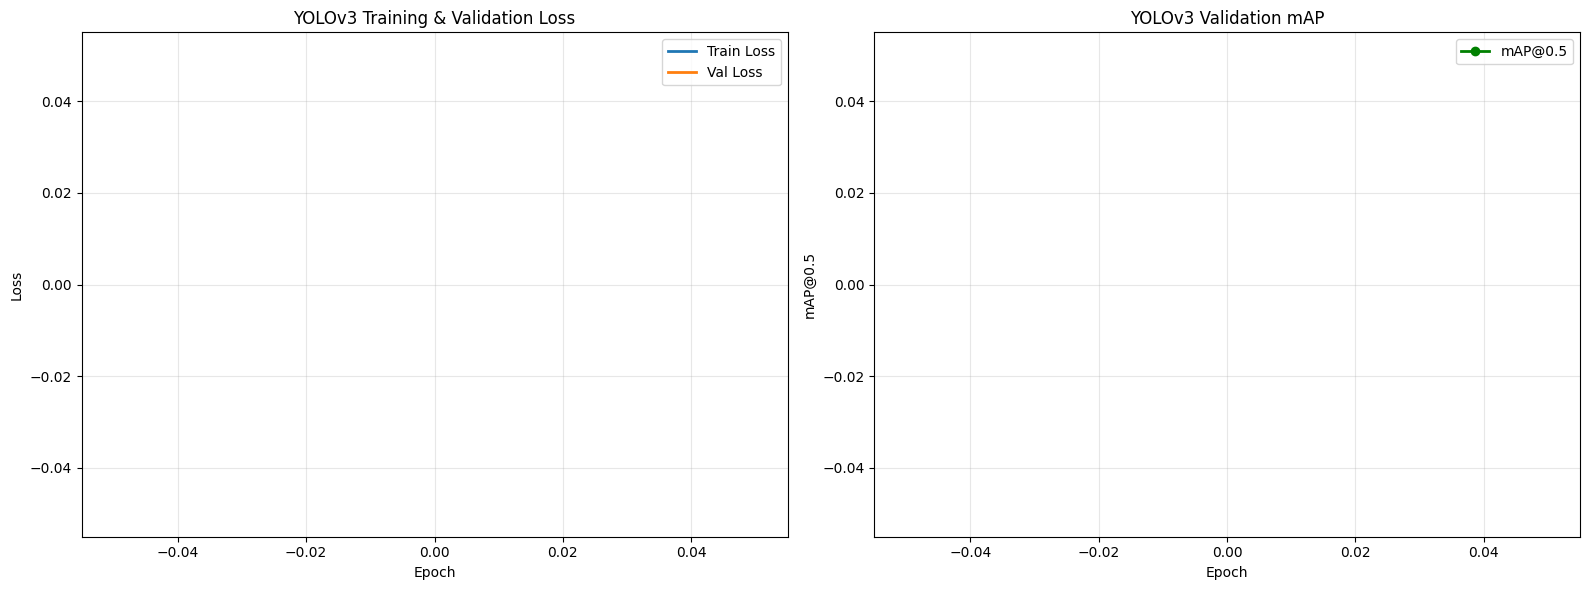

In [75]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
epochs_range = range(1, len(train_losses) + 1)

# Loss curves
axes[0].plot(epochs_range, train_losses, label="Train Loss", linewidth=2)
axes[0].plot(epochs_range, val_losses, label="Val Loss", linewidth=2)
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].set_title("YOLOv3 Training & Validation Loss")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# mAP curve (only non-zero values)
map_epochs = [i + 1 for i, m in enumerate(val_maps) if m > 0]
map_values = [m for m in val_maps if m > 0]
axes[1].plot(map_epochs, map_values, "o-", label="mAP@0.5", linewidth=2, color="green")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("mAP@0.5")
axes[1].set_title("YOLOv3 Validation mAP")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig("yolov3_training_curves.png", dpi=150, bbox_inches="tight")
plt.show()


# 9. Evaluation on Validation Set

In [76]:
import numpy as np
import torch
from torch.utils.data import DataLoader

# -------------------------------------------------------------------------
# Step 1: Collect per-image detections and GT boxes
# -------------------------------------------------------------------------
model.eval()

all_det_scores = {c: [] for c in range(NUM_CLASSES)}
all_det_is_tp = {c: [] for c in range(NUM_CLASSES)}
n_gt_per_class = {c: 0 for c in range(NUM_CLASSES)}

eval_loop = tqdm(val_loader, desc="Evaluating", leave=False)

with torch.no_grad():
    for images, gt_boxes_list, gt_labels_list in eval_loop:
        images = images.to(device)

        # Run YOLOv3 detection
        detections = detect_objects(
            model,
            images,
            anchors=ANCHORS,
            strides=STRIDES,
            img_size=IMG_SIZE,
            num_classes=NUM_CLASSES,
            conf_threshold=0.01,
            nms_threshold=NMS_THRESHOLD,
        )

        # -------------------------------------------------------------------------
        # Step 2: Match detections to GT boxes (greedy IoU matching)
        # -------------------------------------------------------------------------
        for idx in range(len(detections)):
            det = detections[idx]
            gt_boxes = gt_boxes_list[idx].to(device)
            gt_labels = gt_labels_list[idx].to(device)

            for c in range(NUM_CLASSES):
                n_gt_per_class[c] += (gt_labels == c).sum().item()

            gt_matched = torch.zeros(gt_boxes.size(0), dtype=torch.bool, device=device)

            for det_idx in range(det["boxes"].size(0)):
                det_box = det["boxes"][det_idx].unsqueeze(0)
                det_label = det["labels"][det_idx].item()
                det_score = det["scores"][det_idx].item()

                class_mask = gt_labels == det_label
                if class_mask.sum() == 0:
                    all_det_scores[det_label].append(det_score)
                    all_det_is_tp[det_label].append(False)
                    continue

                gt_class_boxes = gt_boxes[class_mask]
                gt_class_indices = torch.where(class_mask)[0]
                iou = compute_iou(det_box, gt_class_boxes).squeeze(0)
                best_iou, best_gt_local_idx = iou.max(dim=0)
                best_gt_global_idx = gt_class_indices[best_gt_local_idx]

                if best_iou >= 0.5 and not gt_matched[best_gt_global_idx]:
                    all_det_scores[det_label].append(det_score)
                    all_det_is_tp[det_label].append(True)
                    gt_matched[best_gt_global_idx] = True
                else:
                    all_det_scores[det_label].append(det_score)
                    all_det_is_tp[det_label].append(False)

# -------------------------------------------------------------------------
# Step 3: Compute VOC 11-point interpolated AP per class and overall mAP@0.5
# -------------------------------------------------------------------------
print("\n--- Per-Class Results ---")
aps = []

for c in range(NUM_CLASSES):
    n_gt = n_gt_per_class[c]
    class_name = CLASS_NAMES[c]

    if n_gt == 0:
        print(f"  {class_name:12s}: no GT objects")
        continue

    scores = np.array(all_det_scores[c])
    is_tp = np.array(all_det_is_tp[c], dtype=bool)

    if len(scores) == 0:
        print(f"  {class_name:12s}: AP = 0.0000 ({n_gt} GT objects, 0 detections)")
        aps.append(0.0)
        continue

    sort_idx = np.argsort(-scores)
    is_tp = is_tp[sort_idx]

    tp_cumsum = np.cumsum(is_tp)
    fp_cumsum = np.cumsum(~is_tp)
    recall = tp_cumsum / n_gt
    precision = tp_cumsum / (tp_cumsum + fp_cumsum)

    ap = 0.0
    for t in np.arange(0.0, 1.1, 0.1):
        prec_at_recall = precision[recall >= t]
        if len(prec_at_recall) > 0:
            ap += prec_at_recall.max()
    ap /= 11.0

    aps.append(ap)
    print(f"  {class_name:12s}: AP = {ap:.4f} ({n_gt} GT objects)")

val_map_final = np.mean(aps) if len(aps) > 0 else 0.0
print(f"\nVal mAP@0.5: {val_map_final:.4f}")


Evaluating:   0%|          | 0/310 [00:00<?, ?it/s]


--- Per-Class Results ---
  aeroplane   : AP = 0.0010 (285 GT objects)
  bicycle     : AP = 0.0006 (337 GT objects)
  bird        : AP = 0.0004 (459 GT objects)
  boat        : AP = 0.0006 (263 GT objects)
  bottle      : AP = 0.0001 (469 GT objects)
  bus         : AP = 0.0038 (213 GT objects)
  car         : AP = 0.0033 (1201 GT objects)
  cat         : AP = 0.0138 (358 GT objects)
  chair       : AP = 0.0061 (756 GT objects)
  cow         : AP = 0.0004 (244 GT objects)
  diningtable : AP = 0.0012 (206 GT objects)
  dog         : AP = 0.0020 (489 GT objects)
  horse       : AP = 0.0037 (348 GT objects)
  motorbike   : AP = 0.0002 (325 GT objects)
  person      : AP = 0.0338 (4528 GT objects)
  pottedplant : AP = 0.0008 (480 GT objects)
  sheep       : AP = 0.0003 (242 GT objects)
  sofa        : AP = 0.0007 (239 GT objects)
  train       : AP = 0.0006 (282 GT objects)
  tvmonitor   : AP = 0.0001 (308 GT objects)

Val mAP@0.5: 0.0037


# 10. Visualization of Detections
Run detections on sample test images and visualize the predicted bounding boxes with class labels and confidence scores.

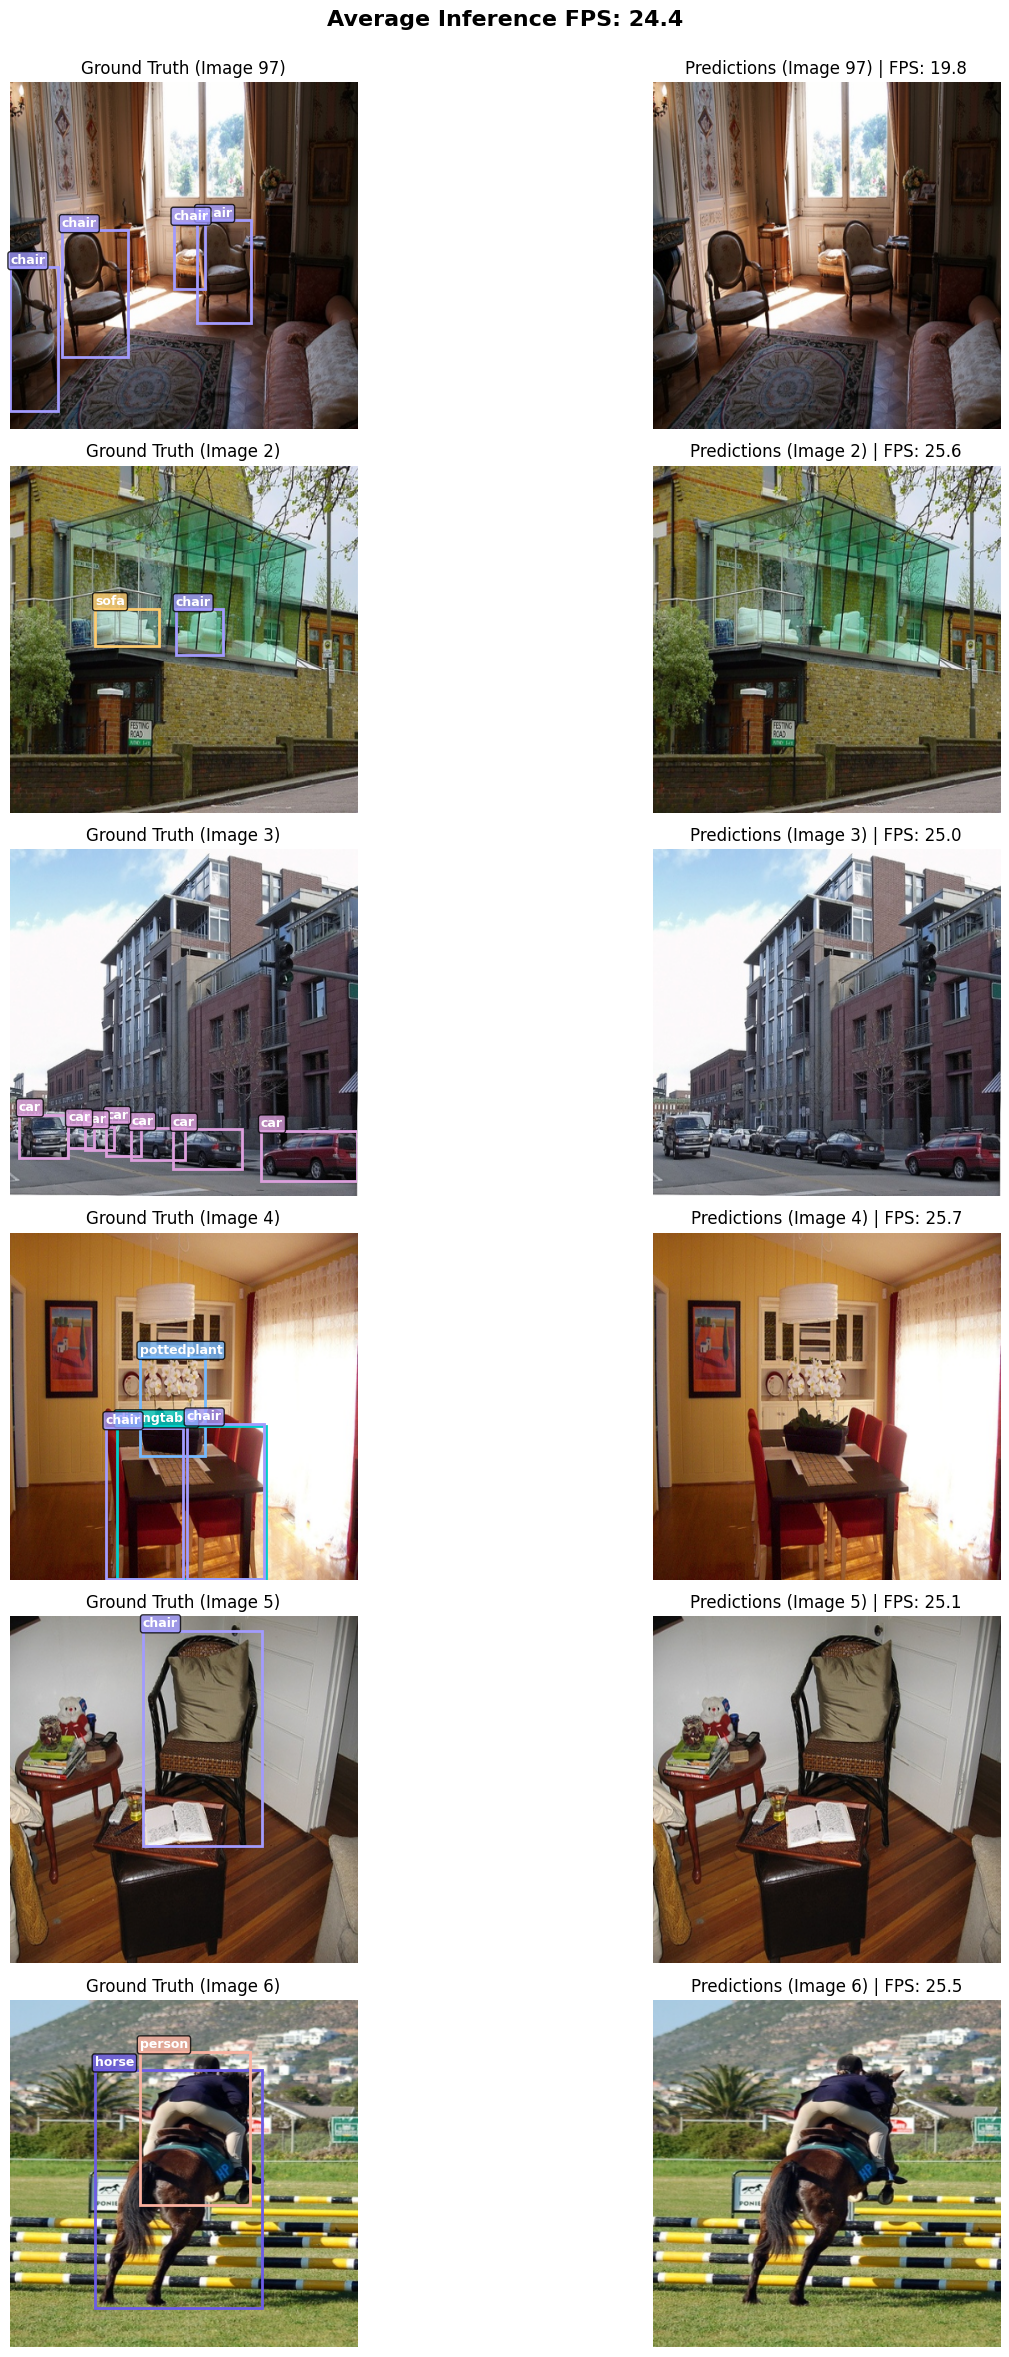

In [77]:
import time

# Color palette for each class (distinct colors for visualization)
CLASS_COLORS = [
    "black",  # 0:  background (not used)
    "#FF6B6B",  # 1:  aeroplane    (red)
    "#4ECDC4",  # 2:  bicycle      (teal)
    "#45B7D1",  # 3:  bird         (blue)
    "#96CEB4",  # 4:  boat         (green)
    "#FFEAA7",  # 5:  bottle       (yellow)
    "#DDA0DD",  # 6:  bus          (plum)
    "#FF8C42",  # 7:  car          (orange)
    "#A29BFE",  # 8:  cat          (lavender)
    "#FD79A8",  # 9:  chair        (pink)
    "#00CEC9",  # 10: cow          (cyan)
    "#E17055",  # 11: diningtable  (burnt orange)
    "#6C5CE7",  # 12: dog          (purple)
    "#55EFC4",  # 13: horse        (mint)
    "#FAB1A0",  # 14: motorbike    (salmon)
    "#74B9FF",  # 15: person       (sky blue)
    "#81ECEC",  # 16: pottedplant  (aqua)
    "#FDCB6E",  # 17: sheep        (gold)
    "#E84393",  # 18: sofa         (magenta)
    "#00B894",  # 19: train        (emerald)
    "#636E72",  # 20: tvmonitor    (grey)
]


# ImageNet denormalization for visualization
def denormalize(tensor):
    """Reverse ImageNet normalization for display."""
    mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
    std = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)
    return torch.clamp(tensor.cpu() * std + mean, 0, 1)


def visualize_detections(
    model, dataset, n_samples=8, conf_threshold=0.3, fixed_indices=None
):
    """Visualize object detections on sample images and calculate FPS.

    Shows side-by-side: (left) ground-truth boxes, (right) predicted boxes.
    """
    model.eval()

    # 1. Use fixed indices if provided to ensure the same images are used across different models
    if fixed_indices is not None:
        indices = fixed_indices[:n_samples]
    else:
        indices = random.sample(range(len(dataset)), min(n_samples, len(dataset)))

    fig, axes = plt.subplots(len(indices), 2, figsize=(16, 4 * len(indices)))
    if len(indices) == 1:
        axes = axes.reshape(1, 2)

    total_fps = 0.0

    for row, idx in enumerate(indices):
        image, gt_boxes, gt_labels = dataset[idx]

        image_batch = image.unsqueeze(0).to(device)

        # 2. FPS Calculation
        # Synchronize before starting the timer to ensure accurate measurement on GPU
        if device.type == "cuda":
            torch.cuda.synchronize()
        start_time = time.time()

        # Disable gradient calculation for faster inference
        with torch.no_grad():
            detections = detect_objects(
                model,
                image_batch,
                anchors=ANCHORS,
                strides=STRIDES,
                img_size=IMG_SIZE,
                num_classes=NUM_CLASSES,
                conf_threshold=conf_threshold,
                nms_threshold=NMS_THRESHOLD,
            )[0]

        # Synchronize again before stopping the timer
        if device.type == "cuda":
            torch.cuda.synchronize()
        end_time = time.time()

        # Calculate FPS for the current image
        inference_time = end_time - start_time
        fps = 1.0 / inference_time if inference_time > 0 else 0.0
        total_fps += fps

        # Denormalize image for display
        img_display = denormalize(image).permute(1, 2, 0).numpy()

        # --- Ground Truth (left column) ---
        axes[row, 0].imshow(img_display)
        axes[row, 0].set_title(f"Ground Truth (Image {idx})", fontsize=12)
        axes[row, 0].axis("off")

        for j in range(gt_boxes.size(0)):
            box = gt_boxes[j].numpy() * IMG_SIZE  # Scale to pixel coords
            label = gt_labels[j].item()
            color = CLASS_COLORS[label]
            rect = patches.Rectangle(
                (box[0], box[1]),
                box[2] - box[0],
                box[3] - box[1],
                linewidth=2,
                edgecolor=color,
                facecolor="none",
            )
            axes[row, 0].add_patch(rect)
            axes[row, 0].text(
                box[0],
                box[1] - 4,
                CLASS_NAMES[label],
                color="white",
                fontsize=9,
                fontweight="bold",
                bbox=dict(boxstyle="round,pad=0.2", facecolor=color, alpha=0.8),
            )

        # --- Predictions (right column) ---
        axes[row, 1].imshow(img_display)
        # Display FPS in the title of the prediction
        axes[row, 1].set_title(
            f"Predictions (Image {idx}) | FPS: {fps:.1f}", fontsize=12
        )
        axes[row, 1].axis("off")

        det_boxes = detections["boxes"].cpu()
        det_labels = detections["labels"].cpu()
        det_scores = detections["scores"].cpu()

        for j in range(det_boxes.size(0)):
            box = det_boxes[j].numpy() * IMG_SIZE
            label = det_labels[j].item()
            score = det_scores[j].item()
            color = CLASS_COLORS[label]
            rect = patches.Rectangle(
                (box[0], box[1]),
                box[2] - box[0],
                box[3] - box[1],
                linewidth=2,
                edgecolor=color,
                facecolor="none",
            )
            axes[row, 1].add_patch(rect)
            axes[row, 1].text(
                box[0],
                box[1] - 4,
                f"{CLASS_NAMES[label]} {score:.2f}",
                color="white",
                fontsize=9,
                fontweight="bold",
                bbox=dict(boxstyle="round,pad=0.2", facecolor=color, alpha=0.8),
            )

    # Display the average FPS over all sample images
    avg_fps = total_fps / len(indices)
    plt.suptitle(
        f"Average Inference FPS: {avg_fps:.1f}", fontsize=16, fontweight="bold"
    )
    plt.tight_layout()
    plt.subplots_adjust(top=0.95)  # Adjust layout to fit the suptitle
    plt.show()


# Define common indices to be used across all your notebooks (SSD, YOLO, RCNN)
common_eval_indices = [97, 2, 3, 4, 5, 6]
visualize_detections(
    model,
    val_dataset,
    n_samples=6,
    fixed_indices=common_eval_indices,
    conf_threshold=CONF_THRESHOLD,
)
